# [CSCI 3345] Course Project: Baseline Checkpoint

**Team 2:** Jacelyn Tay, Rou Jing Chan, Vansh Puri

**Project:** Evaluating SMS Spam Classifiers Under Distribution Shift: Robustness and Adaptation

## Project Overview

SMS spam detection is a binary classification task that distinguishes legitimate messages (ham) from spam or smishing messages.

This project investigates how well SMS spam classifiers trained on historical data generalize to non-overlapping messages from a second corpus, and whether different classifiers, feature representations, and limited adaptation can improve cross-corpus performance.

**Core Question:** How does the performance of SMS spam classifiers change under cross-corpus distribution shift, and to what extent can different models, features, and limited adaptation improve generalization?

**Baseline Checkpoint:** Build a reproducible data and evaluation pipeline, train a simple baseline classifier, report initial validation results, and examine where the baseline fails.


## 1. Experimental Setup

We first establish a baseline using the UCI SMS Spam Collection dataset.

| Component | Baseline setup |
|---|---|
| Input | SMS message text |
| Target | Ham (0) or spam/smishing (1) |
| Training data | UCI SMS Spam Collection |
| Features | Binary bag-of-words |
| Baseline | L2-regularized logistic regression |
| Reference | Majority-class classifier |
| Primary metric | Average Precision (AP) |
| Secondary metrics | Precision, recall, F1, false-positive rate |

**Data splits:** We use stratified 70% training, 15% validation, and 15% test splits for UCI. The Mendeley SMS Phishing Dataset is reserved for cross-corpus evaluation and limited-data adaptation.

**Evaluation rule:** Fit preprocessing and models using training data only. Use validation data for model selection and initial evaluation. Keep the final test sets untouched until the final evaluation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    average_precision_score, precision_score, recall_score,
    f1_score, confusion_matrix, precision_recall_curve
)
from sklearn.tree import DecisionTreeClassifier

SEED = 3345
np.random.seed(SEED)
np.set_printoptions(precision=4, suppress=True)

## 2. Data Loading and Exploration

We use the UCI SMS Spam Collection as our historical dataset for training and in-domain evaluation.

The dataset contains 5,574 English SMS messages, labelled as ham (legitimate) or spam. We first inspect its structure, class distribution, and data quality before preprocessing.

In [2]:
import csv

# Load UCI SMS Spam Collection
uci = pd.read_csv('SMSSpamCollection', sep='\t', header=None,
                  names=['label', 'text'], encoding='utf-8',
                  quoting=csv.QUOTE_NONE)

print('Dataset shape:', uci.shape)
display(uci.assign(message_length=uci['text'].str.len())[
    ['label', 'message_length']
].head())

print('\nClass distribution:')
print(uci['label'].value_counts())

print('\nMissing values:')
print(uci.isna().sum())

Dataset shape: (5574, 2)


,label,message_length
0,ham,111
1,ham,29
2,spam,155
3,ham,49
4,ham,61



Class distribution:
label
ham     4827
spam     747
Name: count, dtype: int64

Missing values:
label    0
text     0
dtype: int64


### 2.1 Class Distribution and Duplicates

We examine the class proportions and identify duplicate messages before splitting the dataset. This helps us account for class imbalance and prevent data leakage between training and evaluation sets.

In [3]:
print('Class distribution (%):')
print((uci['label'].value_counts(normalize=True) * 100).round(2))

print('\nDuplicate messages:', uci['text'].duplicated().sum())
print('Duplicate rows:', uci.duplicated().sum())

# Check whether identical messages have conflicting labels
conflicts = uci.groupby('text')['label'].nunique()
print('Messages with conflicting labels:', (conflicts > 1).sum())

Class distribution (%):
label
ham     86.6
spam    13.4
Name: proportion, dtype: float64

Duplicate messages: 403
Duplicate rows: 403
Messages with conflicting labels: 0


The UCI dataset is imbalanced, with 86.6% ham and 13.4% spam. We also identified 403 duplicate messages, with no conflicting labels. Exact duplicates will be removed before splitting to prevent data leakage.

### 2.2 Mendeley SMS Phishing Dataset

We use the Mendeley SMS Phishing Dataset (2022) for cross-corpus evaluation and limited-data adaptation.

The dataset contains 5,971 messages classified as ham, spam, or smishing. We inspect its structure and label distribution before harmonizing the labels with the UCI dataset.

In [4]:
# Load Mendeley SMS Phishing Dataset
mendeley = pd.read_csv('Dataset_5971.csv')

print('Dataset shape:', mendeley.shape)
display(mendeley.assign(message_length=mendeley['TEXT'].str.len())[
    ['LABEL', 'message_length', 'URL', 'EMAIL', 'PHONE']
].head())

print('\nClass distribution:')
print(mendeley['LABEL'].value_counts())

print('\nMissing values:')
print(mendeley.isna().sum())

print('\nDuplicate messages:', mendeley['TEXT'].duplicated().sum())
print('Duplicate rows:', mendeley.duplicated().sum())

print('\nUnique labels:', mendeley['LABEL'].unique())

Dataset shape: (5971, 5)


,LABEL,message_length,URL,EMAIL,PHONE
0,ham,136,No,No,No
1,ham,79,No,No,No
2,ham,28,No,No,No
3,ham,173,No,No,No
4,Smishing,152,No,No,No



Class distribution:
LABEL
ham         4844
Smishing     616
spam         466
Spam          23
smishing      22
Name: count, dtype: int64

Missing values:
LABEL    0
TEXT     0
URL      0
EMAIL    0
PHONE    0
dtype: int64

Duplicate messages: 22
Duplicate rows: 17

Unique labels: ['ham' 'Smishing' 'spam' 'Spam' 'smishing']


## 3. Data Preprocessing

We standardize the labels across both datasets, remove duplicate messages, and identify cross-dataset overlap before splitting the data.

We use binary labels:
- **0:** Ham (legitimate SMS)
- **1:** Spam or smishing

To prevent data leakage, duplicate and overlapping messages are handled before creating the training, validation, and test sets.

In [5]:
# Standardize column names and labels
uci_clean = uci[['label', 'text']].copy()
mendeley_clean = mendeley[['LABEL', 'TEXT']].copy()
mendeley_clean.columns = ['label', 'text']

label_map = {'ham': 0, 'spam': 1, 'smishing': 1}

for df in [uci_clean, mendeley_clean]:
    df['label'] = df['label'].str.strip().str.lower().map(label_map)

print('UCI class distribution:')
print(uci_clean['label'].value_counts().sort_index())

print('\nMendeley class distribution:')
print(mendeley_clean['label'].value_counts().sort_index())

print('\nUnmapped labels:')
print('UCI:', uci_clean['label'].isna().sum())
print('Mendeley:', mendeley_clean['label'].isna().sum())

UCI class distribution:
label
0    4827
1     747
Name: count, dtype: int64

Mendeley class distribution:
label
0    4844
1    1127
Name: count, dtype: int64

Unmapped labels:
UCI: 0
Mendeley: 0


### 3.1 Duplicate and Cross-Dataset Overlap Detection

We identify duplicate messages within each dataset and overlapping messages between UCI and Mendeley.

For duplicate detection, we standardize whitespace and capitalization while preserving the original message text for model training. We also check for conflicting labels before removing duplicates.

In [6]:
# Normalize text for duplicate detection
for df in [uci_clean, mendeley_clean]:
    df['text_key'] = (df['text'].str.strip().str.lower()
                      .str.replace(r'\s+', ' ', regex=True))

# Check duplicates and conflicting labels
for name, df in [('UCI', uci_clean), ('Mendeley', mendeley_clean)]:
    print(f'{name} duplicate messages:', df['text_key'].duplicated().sum())
    print(f'{name} conflicting labels:',
          (df.groupby('text_key')['label'].nunique() > 1).sum())

# Check overlap between datasets
overlap = set(uci_clean['text_key']) & set(mendeley_clean['text_key'])

print('\nOverlapping unique messages:', len(overlap))
print('Mendeley rows overlapping UCI:',
      mendeley_clean['text_key'].isin(overlap).sum())

UCI duplicate messages: 415
UCI conflicting labels: 0
Mendeley duplicate messages: 140
Mendeley conflicting labels: 0

Overlapping unique messages: 4886
Mendeley rows overlapping UCI: 5025


In [7]:
# Compare labels for overlapping messages
uci_labels = uci_clean.drop_duplicates('text_key').set_index('text_key')['label']
mendeley_labels = mendeley_clean.drop_duplicates('text_key').set_index('text_key')['label']

common_keys = uci_labels.index.intersection(mendeley_labels.index)

print('Overlapping messages:', len(common_keys))
print('Conflicting labels across datasets:',
      (uci_labels.loc[common_keys] != mendeley_labels.loc[common_keys]).sum())

# Examine messages unique to Mendeley
mendeley_unique = mendeley_clean[
    ~mendeley_clean['text_key'].isin(uci_clean['text_key'])
]

print('\nNon-overlapping Mendeley messages:', len(mendeley_unique))

print('\nClass distribution (non-overlapping messages):')
print(mendeley_unique['label'].value_counts().sort_index())

print('\nClass distribution (%):')
print((mendeley_unique['label'].value_counts(normalize=True) * 100).round(2))

Overlapping messages: 4886
Conflicting labels across datasets: 0

Non-overlapping Mendeley messages: 946

Class distribution (non-overlapping messages):
label
0    525
1    421
Name: count, dtype: int64

Class distribution (%):
label
0    55.5
1    44.5
Name: proportion, dtype: float64


### 3.2 Deduplication and Overlap Removal

We remove duplicate messages within each dataset using normalized text. We then exclude Mendeley messages that overlap with UCI to prevent data leakage during cross-corpus evaluation.

The original message text is preserved for feature extraction and model training.

In [8]:
# Remove duplicates within each dataset
uci_data = uci_clean.drop_duplicates(subset='text_key').copy()
mendeley_data = mendeley_clean.drop_duplicates(subset='text_key').copy()

# Remove Mendeley messages overlapping with UCI
mendeley_data = mendeley_data[
    ~mendeley_data['text_key'].isin(uci_data['text_key'])
].copy()

uci_data = uci_data.reset_index(drop=True)
mendeley_data = mendeley_data.reset_index(drop=True)

print('UCI messages:', len(uci_data))
print('Mendeley messages:', len(mendeley_data))

print('\nUCI class distribution:')
print(uci_data['label'].value_counts().sort_index())

print('\nMendeley class distribution:')
print(mendeley_data['label'].value_counts().sort_index())

print('\nRemaining cross-dataset overlap:',
      len(set(uci_data['text_key']) & set(mendeley_data['text_key'])))

UCI messages: 5159
Mendeley messages: 945

UCI class distribution:
label
0    4517
1     642
Name: count, dtype: int64

Mendeley class distribution:
label
0    524
1    421
Name: count, dtype: int64

Remaining cross-dataset overlap: 0


### 3.3 Train/Validation/Test Splitting

We split the deduplicated UCI dataset into 70% training, 15% validation, and 15% test sets using stratified sampling.

The non-overlapping Mendeley dataset is divided equally into an adaptation pool and a held-out cross-corpus test set.

All splits use a fixed random seed for reproducibility. The test sets are reserved for final evaluation and are not used for training or model selection.

In [9]:
# UCI: 70% training, 15% validation, 15% test
uci_train, uci_temp = train_test_split(
    uci_data, test_size=0.30, random_state=SEED,
    stratify=uci_data['label']
)

uci_val, uci_test = train_test_split(
    uci_temp, test_size=0.50, random_state=SEED,
    stratify=uci_temp['label']
)

# Mendeley: 50% adaptation, 50% test
mendeley_adapt, mendeley_test = train_test_split(
    mendeley_data, test_size=0.50, random_state=SEED,
    stratify=mendeley_data['label']
)

# Summarize the splits
splits = {
    'UCI Train': uci_train,
    'UCI Validation': uci_val,
    'UCI Test': uci_test,
    'Mendeley Adaptation': mendeley_adapt,
    'Mendeley Test': mendeley_test
}

split_summary = pd.DataFrame({
    name: {
        'Total': len(df),
        'Ham': (df['label'] == 0).sum(),
        'Spam/Smishing': (df['label'] == 1).sum(),
        'Positive (%)': round(df['label'].mean() * 100, 2)
    }
    for name, df in splits.items()
}).T

display(split_summary)

,Total,Ham,Spam/Smishing,Positive (%)
UCI Train,3611.0,3162.0,449.0,12.43
UCI Validation,774.0,678.0,96.0,12.40
UCI Test,774.0,677.0,97.0,12.53
Mendeley Adaptation,472.0,262.0,210.0,44.49
Mendeley Test,473.0,262.0,211.0,44.61


## 4. Baseline Models

### 4.1 Binary Bag-of-Words Features

We use binary bag-of-words to represent SMS messages as numerical feature vectors. Each feature indicates whether a word appears in a message.

The vocabulary is learned from the UCI training set only and then applied to the validation set to prevent data leakage.

In [10]:
# Prepare training and validation data
X_train_text = uci_train['text']
X_val_text = uci_val['text']

y_train = uci_train['label']
y_val = uci_val['label']

# Binary bag-of-words
vectorizer = CountVectorizer(binary=True)

X_train = vectorizer.fit_transform(X_train_text)
X_val = vectorizer.transform(X_val_text)

print('Training features:', X_train.shape)
print('Validation features:', X_val.shape)
print('Vocabulary size:', len(vectorizer.vocabulary_))

Training features: (3611, 7162)
Validation features: (774, 7162)
Vocabulary size: 7162


### 4.2 Training Baseline Classifiers

We train two classifiers on the UCI training set:

1. **Majority-class classifier:** A simple reference model that always predicts the most frequent class.
2. **Logistic regression:** Our main baseline, using L2 regularization and binary bag-of-words features.

We use the default regularization strength (C = 1.0) and increase the maximum number of iterations to 1000 to ensure convergence.

In [11]:
# Majority-class classifier
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)

# L2-regularized logistic regression
log_reg = LogisticRegression(
    penalty='l2', C=1.0, max_iter=1000, random_state=SEED
)
log_reg.fit(X_train, y_train);

In [12]:
models = {
    'Majority Class': dummy,
    'Logistic Regression': log_reg
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_val)
    y_score = model.predict_proba(X_val)[:, 1]

    tn, fp, fn, tp = confusion_matrix(y_val, y_pred).ravel()

    results.append({
        'Model': name,
        'AP': average_precision_score(y_val, y_score),
        'Precision': precision_score(y_val, y_pred, zero_division=0),
        'Recall': recall_score(y_val, y_pred),
        'F1': f1_score(y_val, y_pred),
        'FPR': fp / (fp + tn)
    })

results_df = pd.DataFrame(results).set_index('Model')
display(results_df.round(4))

,AP,Precision,Recall,F1,FPR
Model,,,,,
Majority Class,0.1240,0.0000,0.000,0.0000,0.0000
Logistic Regression,0.9611,0.9882,0.875,0.9282,0.0015


## 5. Results and Error Analysis

We examine the logistic regression baseline using a confusion matrix and a precision-recall curve on the UCI validation set.

The confusion matrix shows the number of correct and incorrect classifications, while the precision-recall curve illustrates the trade-off between detecting spam and avoiding false positives.

,Predicted Ham,Predicted Spam
Actual Ham,677,1
Actual Spam,12,84


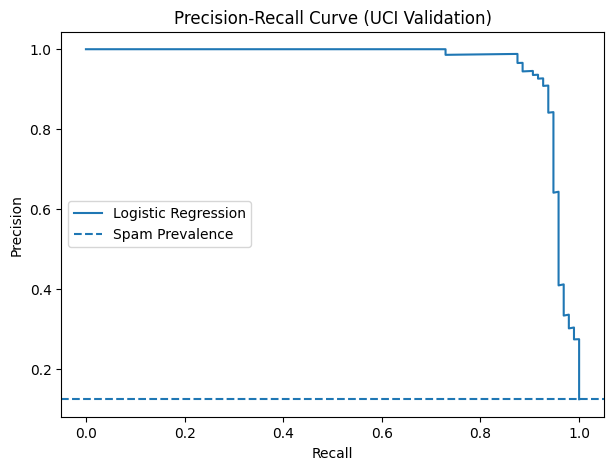

In [13]:
# Logistic regression predictions
y_pred = log_reg.predict(X_val)
y_score = log_reg.predict_proba(X_val)[:, 1]

# Confusion matrix
cm = confusion_matrix(y_val, y_pred)

display(pd.DataFrame(
    cm,
    index=['Actual Ham', 'Actual Spam'],
    columns=['Predicted Ham', 'Predicted Spam']
))

# Precision-recall curve
precision, recall, thresholds = precision_recall_curve(y_val, y_score)

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label='Logistic Regression')
plt.axhline(y=y_val.mean(), linestyle='--',
            label='Spam Prevalence')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (UCI Validation)')
plt.legend()
plt.show()

### 5.1 Error Analysis

We examine false negatives (missed spam) and false positives (legitimate messages incorrectly classified as spam) on the UCI validation set.

We examine the frequency of misclassifications, message lengths, and predicted spam probabilities. Message contents were inspected during development but are excluded from published outputs to protect privacy.

In [14]:
# Identify misclassified messages
errors = uci_val[['text', 'label']].copy()
errors['predicted'] = y_pred
errors['spam_probability'] = y_score
errors['message_length'] = errors['text'].str.len()

false_negatives = errors[
    (errors['label'] == 1) & (errors['predicted'] == 0)
]

false_positives = errors[
    (errors['label'] == 0) & (errors['predicted'] == 1)
]

print('False negatives:', len(false_negatives))
display(false_negatives[['message_length', 'spam_probability']].round(4))

print('\nFalse positives:', len(false_positives))
display(false_positives[['message_length', 'spam_probability']].round(4))

False negatives: 12


,message_length,spam_probability
1122,139,0.3264
408,49,0.0467
1718,33,0.1928
4209,73,0.2953
1421,160,0.0106
19,155,0.3783
3427,152,0.2193
2542,130,0.0094
1811,84,0.0161
2251,119,0.1122



False positives: 1


,message_length,spam_probability
4409,124,0.8904


The logistic regression baseline correctly identifies 84 of 96 spam messages, with only one false positive.

The 12 false negatives include conversational messages, promotional offers, and mobile-service notifications. Several receive very low predicted spam probabilities, suggesting that threshold adjustment alone may not resolve all errors.

The single false positive resembles an automated notification. These findings suggest potential limitations of word-level bag-of-words features, motivating further comparisons with alternative classifiers and feature representations.

## 6. Initial Classifier Comparison

We conduct a preliminary comparison between logistic regression and a decision tree using the same binary bag-of-words representation and UCI data split.

This allows us to examine whether a different classifier improves validation performance while keeping the feature representation fixed.

We use a maximum tree depth of 10 as an initial setting to limit model complexity. Further hyperparameter comparisons will be conducted in Experiment 1.

In [15]:
# Decision tree classifier
tree = DecisionTreeClassifier(max_depth=10, random_state=SEED)
tree.fit(X_train, y_train)

# Evaluate on UCI validation set
tree_pred = tree.predict(X_val)
tree_score = tree.predict_proba(X_val)[:, 1]

tn, fp, fn, tp = confusion_matrix(y_val, tree_pred).ravel()

tree_results = pd.DataFrame({
    'AP': [average_precision_score(y_val, tree_score)],
    'Precision': [precision_score(y_val, tree_pred, zero_division=0)],
    'Recall': [recall_score(y_val, tree_pred)],
    'F1': [f1_score(y_val, tree_pred)],
    'FPR': [fp / (fp + tn)]
}, index=['Decision Tree'])

comparison_df = pd.concat([results_df, tree_results])
display(comparison_df.round(4))

,AP,Precision,Recall,F1,FPR
Majority Class,0.1240,0.0000,0.0000,0.0000,0.0000
Logistic Regression,0.9611,0.9882,0.8750,0.9282,0.0015
Decision Tree,0.7649,0.8778,0.8229,0.8495,0.0162


## 7. Preliminary Findings and Next Experiments

### 7.1 Preliminary Findings

Our baseline experiments produced the following findings:

1. **Dataset overlap:** 4,886 unique messages overlap between UCI and Mendeley. After deduplication and overlap removal, 5,159 UCI messages and 945 non-overlapping Mendeley messages remain.

2. **Class imbalance:** The cleaned UCI dataset contains approximately 12.4% spam, while the non-overlapping Mendeley dataset contains approximately 44.6% spam/smishing. These differences must be considered when interpreting Average Precision across datasets.

3. **Baseline performance:** L2-regularized logistic regression achieves an AP of 0.9611 and F1-score of 0.9282 on the UCI validation set, outperforming both the majority-class reference and the preliminary decision tree.

4. **Error analysis:** Logistic regression misses 12 spam messages and incorrectly flags one ham message. The missed spam includes conversational and promotional messages, suggesting potential limitations of word-level bag-of-words features.

These results establish strong in-domain baseline performance. However, cross-corpus generalization remains untested.

### 7.2 Planned Experiments

We will conduct three experiments to investigate cross-corpus generalization:

**Experiment 1: Classifier Comparison**

Compare logistic regression, k-nearest neighbors, and decision trees using the same feature representation. We will investigate whether classifier choice affects robustness under distribution shift.

**Experiment 2: Feature Comparison**

Compare binary bag-of-words, word-level TF-IDF, and character n-gram representations while holding the classifier fixed. We will investigate whether alternative text representations improve robustness to vocabulary and spelling variations.

**Experiment 3: Limited-Data Adaptation**

Using a fixed model configuration, incorporate increasing amounts of labeled data from the Mendeley adaptation pool. We will investigate whether limited target-corpus data improves cross-corpus performance.

Hyperparameter selection and model comparisons will use appropriate training and validation data. The reserved UCI and Mendeley test sets will remain untouched until final evaluation.

### 7.3 Limitations

The Mendeley dataset exhibits substantial overlap with UCI, leaving only 945 non-overlapping messages. The remaining subset also has a different class distribution, making direct performance comparisons sensitive to class prevalence.

Publication dates do not necessarily reflect message collection dates, so the study will focus on cross-corpus rather than strictly temporal generalization.

Our current results are limited to UCI validation performance. Further experiments are needed to evaluate robustness under distribution shift.

In [16]:
# Verify that dataset partitions do not overlap
split_keys = {
    name: set(df['text_key'])
    for name, df in splits.items()
}

names = list(split_keys)

for i in range(len(names)):
    for j in range(i + 1, len(names)):
        assert split_keys[names[i]].isdisjoint(split_keys[names[j]])

print('All dataset splits are disjoint.')

All dataset splits are disjoint.


### 7.4 Reproducibility

All experiments use Python and scikit-learn with a fixed random seed (3345). The same preprocessing, feature representation, and data splits are used for the baseline comparison.

The notebook was executed from a fresh kernel, and all results were reproduced successfully. Dataset sources and setup instructions will be documented in the GitHub repository.